In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import optimize
from sklearn.cluster import KMeans
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from bs4 import BeautifulSoup
import requests
import re
import time

In [2]:
# URL stranice s tablicom nutritivnih vrijednosti
url = "https://tomislavgustin.com/tablica-kalorijske-i-nutritivne-vrijednosti-namirnica/"

# Slanje GET zahtjeva na URL
response = requests.get(url)
response.raise_for_status()

# Parsiranje sadržaja stranice pomoću BeautifulSoup
soup = BeautifulSoup(response.text, 'html.parser')

# Pronalazak svih tablica na stranici
tables = soup.find_all('table')

# Inicijalizacija praznog DataFrame-a za pohranu podataka
df = pd.DataFrame()

# Iteracija kroz pronađene tablice i ekstrakcija podataka
for table in tables:
    # Ekstrakcija podataka iz tablice pomoću pandas
    table_df = pd.read_html(str(table), header=0, decimal=',', thousands='.')[0]

    # Ekstrakcija prvog stupca ručno
    rows = table.find_all('tr')[1:]
    namirnice = [row.find_all('td')[0].get_text(strip=True) for row in rows if row.find_all('td')]

    # Dodavanje stupca u DataFrame
    table_df.insert(0, 'Namirnica', namirnice)

    # Pretvaranje brojeva s decimalnim zarezom u float za sve numeričke stupce
    for col in table_df.columns:
        if col != 'Namirnica':  # Izbjegavanje pretvorbe tekstualnog stupca
            table_df[col] = pd.to_numeric(table_df[col], errors='coerce')

    # Brisanje stupca 'Energija'
    if 'Energija' in table_df.columns:
        table_df.drop(columns=['Energija'], inplace=True)

    # Preimenovanje stupca 'Energija.1' u 'Kalorije'
    if 'Energija.1' in table_df.columns:
        table_df.rename(columns={'Energija.1': 'Kalorije'}, inplace=True)

    # Dodavanje podataka u glavni DataFrame
    df = pd.concat([df, table_df], ignore_index=True)

# Brisanje praznog stupca
df = df.drop("Namirnica (100 g)", axis=1)
# Spremanje rezultata u CSV datoteku
output_file = "nutrijenti.csv"
df.to_csv(output_file, index=False, encoding='utf-8')
print(f"Podaci su spremljeni u datoteku: {output_file}")

<ipython-input-2-afb27c56d0d4>:20: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  table_df = pd.read_html(str(table), header=0, decimal=',', thousands='.')[0]
<ipython-input-2-afb27c56d0d4>:20: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  table_df = pd.read_html(str(table), header=0, decimal=',', thousands='.')[0]
<ipython-input-2-afb27c56d0d4>:20: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  table_df = pd.read_html(str(table), header=0, decimal=',', thousands='.')[0]
<ipython-input-2-afb27c56d0d4>:20: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read fr

Podaci su spremljeni u datoteku: nutrijenti.csv


<ipython-input-2-afb27c56d0d4>:20: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  table_df = pd.read_html(str(table), header=0, decimal=',', thousands='.')[0]
<ipython-input-2-afb27c56d0d4>:20: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  table_df = pd.read_html(str(table), header=0, decimal=',', thousands='.')[0]
<ipython-input-2-afb27c56d0d4>:20: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  table_df = pd.read_html(str(table), header=0, decimal=',', thousands='.')[0]
<ipython-input-2-afb27c56d0d4>:20: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read fr

In [3]:
df = pd.read_csv('/content/nutrijenti.csv')

# Izbacivanje prvog retka
df = df.iloc[1:]

# Preimenovanje stupaca
df.rename(columns={'Namirnica': 'Namirnica (100g)', 'Kalorije': 'Kalorije (kcal)', 'Masti': 'Masti (g)', 'UH': 'UH (g)', 'Bjelančevine': 'Proteini (g)'}, inplace=True)

df.to_csv('nutrijenti.csv', index=False)

print("Podaci su uspješno izmijenjeni i spremljeni u nutrijenti.csv")

Podaci su uspješno izmijenjeni i spremljeni u nutrijenti.csv


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 1 to 178
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Namirnica (100g)  167 non-null    object 
 1   Kalorije (kcal)   166 non-null    float64
 2   UH (g)            166 non-null    float64
 3   Proteini (g)      164 non-null    float64
 4   Masti (g)         165 non-null    float64
dtypes: float64(4), object(1)
memory usage: 7.1+ KB


In [5]:
df.head()

,Namirnica (100g),Kalorije (kcal),UH (g),Proteini (g),Masti (g)
1,"Mlijeko (0,5 % m.m)",36.0,4.7,3.3,0.5
2,"Mlijeko (2,8 % m.m)",57.0,4.7,3.3,2.8
3,Jogurt (obični),48.0,4.7,4.0,3.3
4,Kiselo vrhnje (10% m.m),127.0,4.0,3.1,10.5
5,Slatko vrhnje,342.0,2.6,1.9,36.0


In [6]:
df.isnull().sum()

,0
Namirnica (100g),11
Kalorije (kcal),12
UH (g),12
Proteini (g),14
Masti (g),13


In [7]:
# Uklanjanje redaka s NaN vrijednostima
df = df.dropna()

df.to_csv('nutrijenti_očišćeni.csv', index=False)

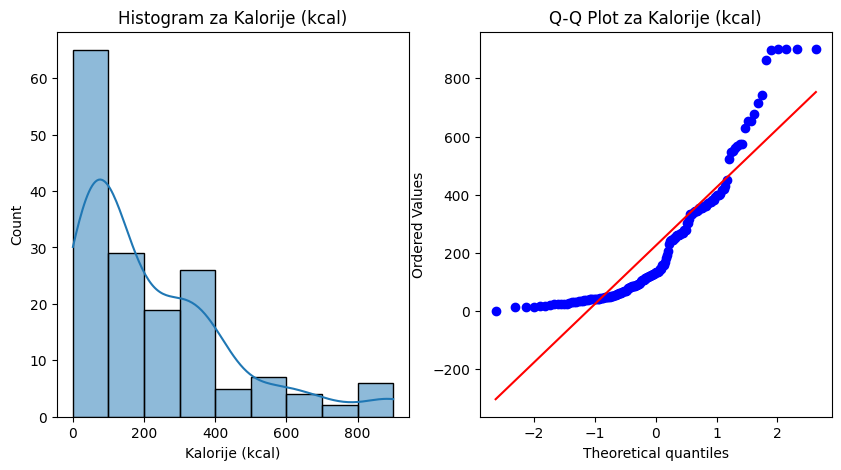

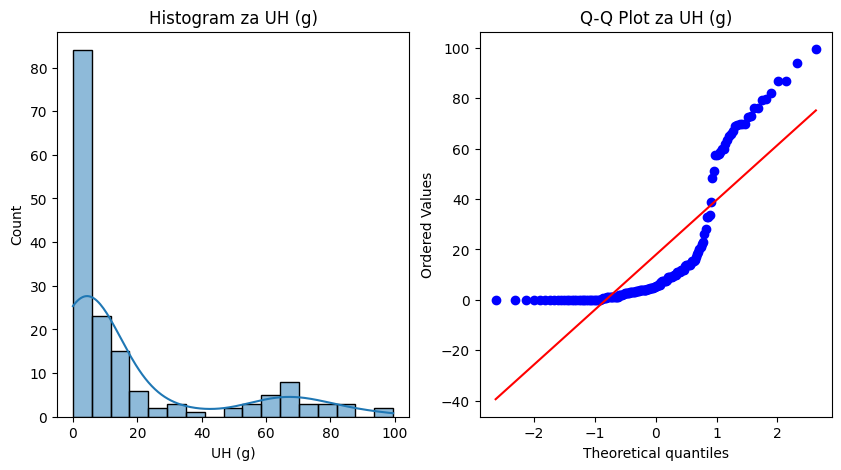

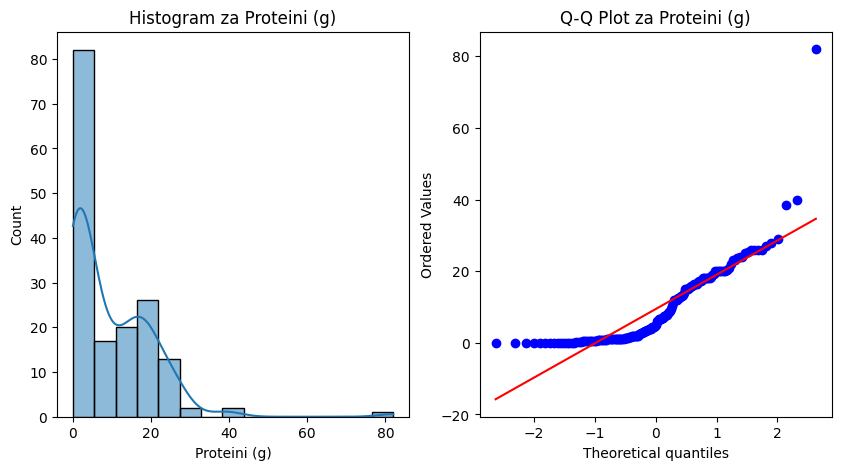

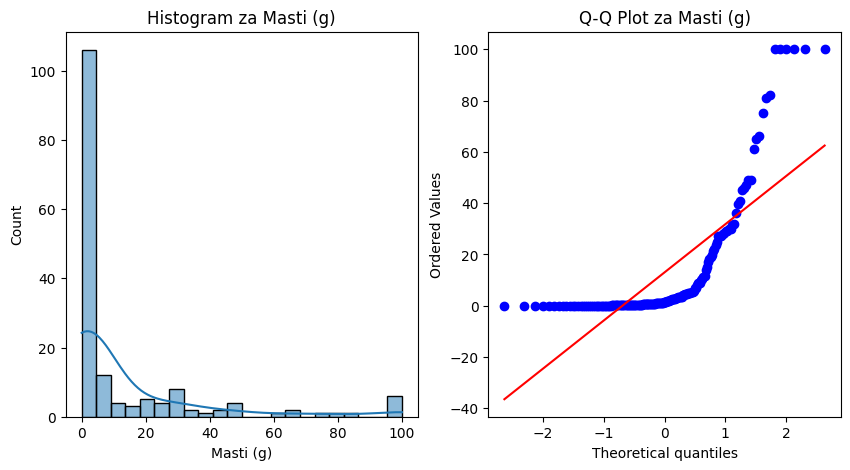

In [8]:
import scipy.stats as stats

# Odabir numeričkih stupaca za provjeru
numeric_columns = df.select_dtypes(include=['number']).columns

# Kreiranje histograma i Q-Q plotova za svaki numerički stupac
for column in numeric_columns:
    plt.figure(figsize=(10, 5))

    # Histogram
    plt.subplot(1, 2, 1)
    sns.histplot(df[column], kde=True)
    plt.title(f'Histogram za {column}')

    # Q-Q plot
    plt.subplot(1, 2, 2)
    stats.probplot(df[column], dist="norm", plot=plt)
    plt.title(f'Q-Q Plot za {column}')

    plt.show()

Srednje vrijednosti (kalorije, proteini, UH, masti):
[224.95398773  17.86196319   9.45214724  12.99325153]

Standardne devijacije:
[216.84058639  25.7683527   10.76359655  24.00052435]


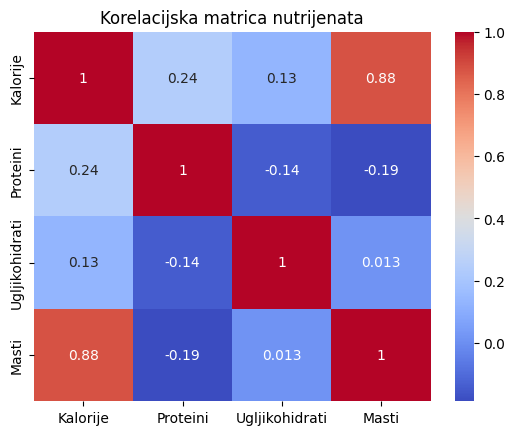

In [9]:
# Pretvorba DataFrame-a u NumPy array
nutrient_matrix = df[['Kalorije (kcal)', 'UH (g)', 'Proteini (g)', 'Masti (g)']].to_numpy()

# Osnovne statistike
mean_values = np.mean(nutrient_matrix, axis=0)
std_values = np.std(nutrient_matrix, axis=0)

# Korelacijska matrica
correlation_matrix = np.corrcoef(nutrient_matrix.T)

# Normalizacija podataka
normalized_matrix = (nutrient_matrix - mean_values) / std_values

# Ispis rezultata
print("Srednje vrijednosti (kalorije, proteini, UH, masti):")
print(mean_values)
print("\nStandardne devijacije:")
print(std_values)

sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm',
            xticklabels=['Kalorije', 'Proteini', 'Ugljikohidrati', 'Masti'],
            yticklabels=['Kalorije', 'Proteini', 'Ugljikohidrati', 'Masti'])

plt.title('Korelacijska matrica nutrijenata')
plt.show()

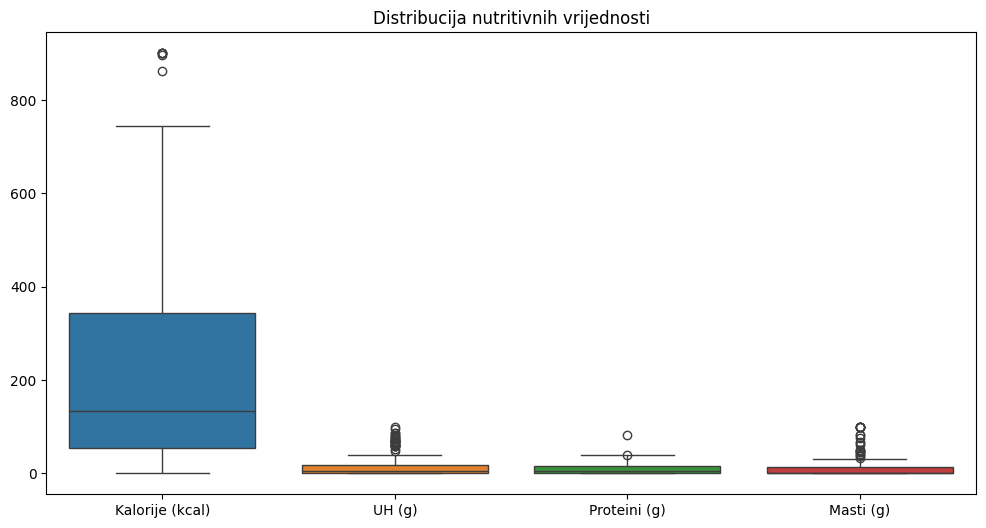

In [10]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df[['Kalorije (kcal)', 'UH (g)', 'Proteini (g)', 'Masti (g)']])
plt.title('Distribucija nutritivnih vrijednosti')
plt.show()

In [11]:
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

X = df[['UH (g)', 'Proteini (g)', 'Masti (g)']]
y = df['Kalorije (kcal)']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Treniranje modela
model = LinearRegression()
model.fit(X_train, y_train)

# Predviđanje i evaluacija
y_pred = model.predict(X_test)

# Metrike evaluacije
print('R² Score:', r2_score(y_test, y_pred))
print('MSE:', mean_squared_error(y_test, y_pred))
print('RMSE:', np.sqrt(mean_squared_error(y_test, y_pred)))
print('MAE:', mean_absolute_error(y_test, y_pred))

# Koeficijenti
for feature, coef in zip(X.columns, model.coef_):
    print(f'{feature}: {coef:.2f}')

R² Score: 0.9917255012625027
MSE: 551.781073200407
RMSE: 23.49002071519749
MAE: 14.973939528087383
UH (g): 3.75
Proteini (g): 3.85
Masti (g): 8.67


In [12]:
import plotly.express as px
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

macronutrients = df[['Kalorije (kcal)', 'UH (g)', 'Proteini (g)', 'Masti (g)']]

# Standardizacija podataka
scaler = StandardScaler()
scaled_data = scaler.fit_transform(macronutrients)

# K-Means klasteriranje
kmeans = KMeans(n_clusters=5, random_state=42)
df['Cluster'] = kmeans.fit_predict(scaled_data)

# Izračun prosječnih vrijednosti za svaki klaster
cluster_centers = pd.DataFrame(
    scaler.inverse_transform(kmeans.cluster_centers_),
    columns=macronutrients.columns
)
cluster_centers['Cluster'] = range(5)

# Dodavanje opisa klastera
cluster_descriptions = []
for _, row in cluster_centers.iterrows():
    description = (
        f"Kalorije: {row['Kalorije (kcal)']:.1f}, "
        f"UH (g): {row['UH (g)']:.1f}, "
        f"Proteini (g): {row['Proteini (g)']:.1f}, "
        f"Masti (g): {row['Masti (g)']:.1f}"
    )
    cluster_descriptions.append(description)

# Zamjena numeričkih oznaka klastera opisima
cluster_mapping = {i: desc for i, desc in enumerate(cluster_descriptions)}
df['Cluster_Description'] = df['Cluster'].map(cluster_mapping)

# PCA za vizualizaciju
pca = PCA(n_components=2)
pca_data = pca.fit_transform(scaled_data)

# Dodavanje PCA komponenti u DataFrame
df['PCA1'] = pca_data[:, 0]
df['PCA2'] = pca_data[:, 1]

# Vizualizacija s Plotly
fig = px.scatter(
    df,
    x='PCA1',
    y='PCA2',
    color='Cluster_Description',
    title='Klasteri namirnica prema nutrijentima',
    labels={
        'PCA1': 'PCA Komponenta 1',
        'PCA2': 'PCA Komponenta 2'
    },
    hover_data=['Kalorije (kcal)', 'UH (g)', 'Proteini (g)', 'Masti (g)']
)

fig.update_traces(marker=dict(size=12, opacity=0.8), selector=dict(mode='markers'))
fig.update_layout(legend_title='Klasteri', width=900, height=600)

fig.show()


In [13]:
!pip install -U google-generativeai

In [14]:
!pip install python-dotenv

In [15]:
import os
from dotenv import load_dotenv
import google.generativeai as genai
from getpass import getpass

load_dotenv()

google_api_key = os.getenv('GOOGLE_API_KEY')

if google_api_key is None:
    print("GOOGLE_API_KEY not found in .env file or environment variables.")
    print("Please set it manually:")
    google_api_key = getpass("Enter your Google API key: ")
    os.environ['GOOGLE_API_KEY'] = google_api_key

genai.configure(api_key=google_api_key)

GOOGLE_API_KEY not found in .env file or environment variables.
Please set it manually:
Enter your Google API key: ··········


In [16]:
model = genai.GenerativeModel('gemini-pro')

In [17]:
user_data = {
    'Dob': 25,
    'Spol': 'M',
    'Visina': 185,
    'Težina': 80,
    'Aktivnost': 1.5,
    'Alergije': ['kikiriki'],
    'Preferencije': ['raznoliko']
}

bmr = 10 * user_data['Težina'] + 6.25 * user_data['Visina'] - 5 * user_data['Dob'] + (5 if user_data['Spol'] == 'M' else -161)
tdee = bmr * user_data['Aktivnost']

print("Procijenjeni dnevni unos kalorija:", tdee)

Procijenjeni dnevni unos kalorija: 2754.375


In [18]:
from scipy.optimize import linprog

calories_per_uh = 4
calories_per_protein = 4
calories_per_fat = 9

# Postavljanje cilja minimizacije ukupne količine hrane
c = [1, 1, 1]

# Ograničenje ukupnog kalorijskog unosa
A_eq = [[calories_per_uh, calories_per_protein, calories_per_fat]]
b_eq = [tdee]

A_ub = [
    [calories_per_uh, 0, 0],  # Maksimalni UH ≤ 65% TDEE
    [0, calories_per_protein, 0],  # Maksimalni proteini ≤ 35% TDEE
    [0, 0, calories_per_fat],  # Maksimalne masti ≤ 35% TDEE
]

b_ub = [0.65 * tdee, 0.35 * tdee, 0.35 * tdee]  # Maksimalne vrijednosti

A_lb = [
    [-calories_per_uh, 0, 0],  # Minimalni UH ≥ 45% TDEE
    [0, -calories_per_protein, 0],  # Minimalni proteini ≥ 10% TDEE
    [0, 0, -calories_per_fat],  # Minimalne masti ≥ 20% TDEE
]
b_lb = [-0.45 * tdee, -0.10 * tdee, -0.20 * tdee]

# Kombiniramo gornja i donja ograničenja
A_ineq = A_ub + A_lb
b_ineq = b_ub + b_lb

# Minimalne količine nutrijenata (granice)
bounds = [(130, None), (100, None), (20, None)]

optimal_meal = linprog(c, A_eq=A_eq, b_eq=b_eq, A_ub=A_ineq, b_ub=b_ineq, bounds=bounds, method="highs")

if optimal_meal.success:
    print("Optimalni udjeli makronutrijenata (g):", optimal_meal.x)
else:
    print("Optimizacija nije uspjela.")

Optimalni udjeli makronutrijenata (g): [309.8671875  137.71875    107.11458333]


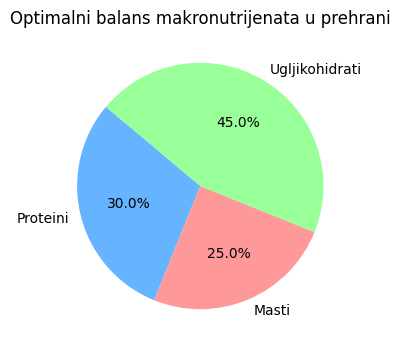

In [19]:
labels = ['Proteini', 'Masti', 'Ugljikohidrati']
optimal_meal = [30, 25, 45]  # Primjer uravnoteženog omjera

plt.figure(figsize=(4, 4))
plt.pie(optimal_meal, labels=labels, colors=['#66b3ff', '#ff9999', '#99ff99'], autopct='%1.1f%%', startangle=140, textprops={'fontsize': 10})
plt.title('Optimalni balans makronutrijenata u prehrani')
plt.show()

In [20]:
products_text = "Dostupni proizvodi s nutritivnim vrijednostima:\n"
for _, product in df.iterrows():
    products_text += f"- {product['Namirnica (100g)']} "
    if 'Kalorije (kcal)' in product:
        products_text += f"kalorije: {product['Kalorije (kcal)']}, "
    if 'UH (g)' in product:
        products_text += f"ugljikohidrati: {product['UH (g)']}g, "
    if 'Proteini (g)' in product:
        products_text += f"proteini: {product['Proteini (g)']}g, "
    if 'Masti (g)' in product:
        products_text += f"masti: {product['Masti (g)']}g"
    products_text += "\n"

print(products_text)


Dostupni proizvodi s nutritivnim vrijednostima:
- Mlijeko (0,5 % m.m) kalorije: 36.0, ugljikohidrati: 4.7g, proteini: 3.3g, masti: 0.5g
- Mlijeko (2,8 % m.m) kalorije: 57.0, ugljikohidrati: 4.7g, proteini: 3.3g, masti: 2.8g
- Jogurt (obični) kalorije: 48.0, ugljikohidrati: 4.7g, proteini: 4.0g, masti: 3.3g
- Kiselo vrhnje (10% m.m) kalorije: 127.0, ugljikohidrati: 4.0g, proteini: 3.1g, masti: 10.5g
- Slatko vrhnje kalorije: 342.0, ugljikohidrati: 2.6g, proteini: 1.9g, masti: 36.0g
- Kefir (3,5 % m.m) kalorije: 65.0, ugljikohidrati: 4.8g, proteini: 3.6g, masti: 3.5g
- ABC svježi krem sir kalorije: 251.0, ugljikohidrati: 3.1g, proteini: 6.7g, masti: 23.5g
- Mozzarella kalorije: 280.0, ugljikohidrati: 3.1g, proteini: 28.0g, masti: 17.0g
- Sir gouda kalorije: 343.0, ugljikohidrati: 2.0g, proteini: 23.0g, masti: 27.0g
- Ementaler kalorije: 261.0, ugljikohidrati: 1.0g, proteini: 27.0g, masti: 28.0g
- Parmezan kalorije: 431.0, ugljikohidrati: 4.0g, proteini: 38.5g, masti: 28.5g
- Polutvrdi si

In [21]:
user_preferences_prompt = f"""
Korisnik ima sljedeće karakteristike:
Dob: {user_data['Dob']} godina
Spol: {user_data['Spol']}
Visina: {user_data['Visina']} cm
Težina: {user_data['Težina']} kg
Fizička aktivnost: {user_data['Aktivnost']}
Alergije: {', '.join(user_data['Alergije'])}
Prehrambene preferencije: {', '.join(user_data['Preferencije'])}

{products_text}

Djeluj kao nutricionist. Koristeći isključivo gore navedene dostupne proizvode iz products_text datoteke,
generiraj personalizirani jelovnik za 3 dana koji uzima u obzir karakteristike korisnika, nutritivne potrebe od {tdee:.2f} kalorija dnevno
i želju da korisnik poveća tjelesnu težinu uzimajući u obzir optimalne vrijednosti makronutrijenata od {optimal_meal}.
Za svaki obrok navedi točne proizvode iz liste i njihove količine.
Objasni kako odabrani proizvodi doprinose nutritivnom balansu.
"""

response = model.generate_content(user_preferences_prompt)
print("Gemini Preporuka:")
print(response.text)

Gemini Preporuka:
**Dan 1**

* **Doručak (988,8 kcal)**
    * Zobene pahuljice (100g): 372 kcal, 58,7g ugljikohidrata, 13,5g proteina, 7,0g masti
    * Banane (200g): 178 kcal, 46g ugljikohidrata, 2g proteina, 0,6g masti
    * Orasi (50g): 327,5 kcal, 13,7g ugljikohidrata, 15g proteina, 32,5g masti
    * Mlijeko (2,8% m.m.) (250ml): 144 kcal, 11,5g ugljikohidrata, 8g proteina, 10g masti

* **Ručak (969,7 kcal)**
    * Pureća prsa (200g): 218 kcal, 0g ugljikohidrata, 50g proteina, 2g masti
    * Krumpir (300g): 255 kcal, 56,7g ugljikohidrata, 6g proteina, 0g masti
    * Brokula (200g): 66 kcal, 14g ugljikohidrata, 5,6g proteina, 0,8g masti
    * Maslinovo ulje (20ml): 180 kcal, 0g ugljikohidrata, 0g proteina, 20g masti

* **Večera (795,8 kcal)**
    * Biftek (250g): 473 kcal, 0g ugljikohidrata, 58g proteina, 16g masti
    * Riža (250g): 923 kcal, 218,8g ugljikohidrata, 18,8g proteina, 1,2g masti
    * Špinat (200g): 46 kcal, 7,2g ugljikohidrata, 5,8g proteina, 0,8g masti
    * Majoneza 

In [22]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

daily_intake = {
    'datum': ['2024-01-01', '2024-01-02', '2024-01-03', '2024-01-04', '2024-01-05', '2024-01-06', '2024-01-07'],
    'kalorije': [2900, 2850, 2950, 3000, 2800, 2900, 2920],
    'proteini': [150, 160, 155, 158, 150, 152, 155],
    'masti': [70, 75, 72, 74, 70, 71, 73],
    'ugljikohidrati': [320, 310, 330, 340, 300, 315, 325],
    'tezina': [80.0, 80.3, 80.7, 81.0, 81.2, 81.3, 81.8]
}

progress_data = pd.DataFrame(daily_intake)
progress_data['datum'] = pd.to_datetime(progress_data['datum'])

fig = make_subplots(rows=3, cols=1, subplot_titles=('Kalorijski unos', 'Makronutrijenti', 'Težina'))

# Kalorijski unos
fig.add_trace(
    go.Scatter(x=progress_data['datum'], y=progress_data['kalorije'],
               name='Dnevni unos', mode='lines+markers'),
    row=1, col=1
)
fig.add_hline(y=2900, line_dash="dash", line_color="red",
              annotation_text="Ciljani unos", row=1, col=1)

# Makronutrijenti
fig.add_trace(
    go.Scatter(x=progress_data['datum'], y=progress_data['proteini'],
               name='Proteini', line=dict(color='blue')),
    row=2, col=1
)
fig.add_trace(
    go.Scatter(x=progress_data['datum'], y=progress_data['masti'],
               name='Masti', line=dict(color='red')),
    row=2, col=1
)
fig.add_trace(
    go.Scatter(x=progress_data['datum'], y=progress_data['ugljikohidrati'],
               name='Ugljikohidrati', line=dict(color='green')),
    row=2, col=1
)

# Težina
fig.add_trace(
    go.Scatter(x=progress_data['datum'], y=progress_data['tezina'],
               name='Težina', line=dict(color='purple')),
    row=3, col=1
)

fig.update_layout(height=900, title_text="Praćenje napretka")
fig.show()

prosjecan_unos_kalorija = progress_data['kalorije'].mean()
odstupanje_od_cilja = progress_data['kalorije'].mean() - tdee
konzistentnost = 1 - (progress_data['kalorije'].std() / progress_data['kalorije'].mean())
prosjecan_unos_proteina = progress_data['proteini'].mean()
prosjecan_unos_masti = progress_data['masti'].mean()
prosjecan_unos_ugljikohidrata = progress_data['ugljikohidrati'].mean()

print("\nAnaliza napretka:")
print(f"Prosječan unos kalorija: {prosjecan_unos_kalorija:.2f}")
print(f"Odstupanje od cilja: {odstupanje_od_cilja:.2f}")
print(f"Konzistentnost: {konzistentnost:.2f}")
print(f"Prosječan unos proteina: {prosjecan_unos_proteina:.2f}g")
print(f"Prosječan unos masti: {prosjecan_unos_masti:.2f}g")
print(f"Prosječan unos ugljikohidrata: {prosjecan_unos_ugljikohidrata:.2f}g")



Analiza napretka:
Prosječan unos kalorija: 2902.86
Odstupanje od cilja: 148.48
Konzistentnost: 0.98
Prosječan unos proteina: 154.29g
Prosječan unos masti: 72.14g
Prosječan unos ugljikohidrata: 320.00g


In [23]:
from scipy import stats

for column in ['kalorije', 'proteini', 'masti', 'ugljikohidrati', 'tezina']:
    slope, intercept, r_value, p_value, std_err = stats.linregress(
        range(len(progress_data)),
        progress_data[column]
    )

    print(f"\nTrend za {column}:")
    print(f"Prosječna dnevna promjena: {slope:.2f}")
    print(f"R² vrijednost: {r_value**2:.3f}")


Trend za kalorije:
Prosječna dnevna promjena: 0.36
R² vrijednost: 0.000

Trend za proteini:
Prosječna dnevna promjena: -0.21
R² vrijednost: 0.014

Trend za masti:
Prosječna dnevna promjena: -0.04
R² vrijednost: 0.002

Trend za ugljikohidrati:
Prosječna dnevna promjena: -0.18
R² vrijednost: 0.001

Trend za tezina:
Prosječna dnevna promjena: 0.28
R² vrijednost: 0.978


In [24]:
kalorije_cilj_postotak = (np.array(daily_intake['kalorije']) / tdee * 100).mean()
proteini_cilj = 2 * user_data['Težina']  # 2g/kg tjelesne težine
proteini_cilj_postotak = (np.array(daily_intake['proteini']) / proteini_cilj * 100).mean()

print("Uspješnost dostizanja cilja:")
print(f"Kalorijski cilj: {kalorije_cilj_postotak:.1f}%")
print(f"Proteinski cilj: {proteini_cilj_postotak:.1f}%")

Uspješnost dostizanja cilja:
Kalorijski cilj: 105.4%
Proteinski cilj: 96.4%


In [25]:
progress_data['datum'] = pd.to_datetime(progress_data['datum'])
progress_data.set_index('datum', inplace=True)

X = np.array(range(len(progress_data))).reshape(-1, 1)

predictions = {}
for column in ['kalorije', 'proteini', 'masti', 'ugljikohidrati', 'tezina']:
    model = LinearRegression()
    model.fit(X, progress_data[column])

    future_days = np.array(range(len(progress_data), len(progress_data) + 7)).reshape(-1, 1)
    predictions[column] = model.predict(future_days)

future_dates = pd.date_range(start=progress_data.index[-1] + pd.Timedelta(days=1), periods=7)
predictions_df = pd.DataFrame(predictions, index=future_dates)

print("Predviđanje za sljedećih 7 dana:")
print(predictions_df)

Predviđanje za sljedećih 7 dana:
               kalorije    proteini      masti  ugljikohidrati     tezina
2024-01-08  2904.285714  153.428571  72.000000      319.285714  82.028571
2024-01-09  2904.642857  153.214286  71.964286      319.107143  82.310714
2024-01-10  2905.000000  153.000000  71.928571      318.928571  82.592857
2024-01-11  2905.357143  152.785714  71.892857      318.750000  82.875000
2024-01-12  2905.714286  152.571429  71.857143      318.571429  83.157143
2024-01-13  2906.071429  152.357143  71.821429      318.392857  83.439286
2024-01-14  2906.428571  152.142857  71.785714      318.214286  83.721429


In [26]:
fig = make_subplots(rows=2, cols=1, subplot_titles=('Kalorije', 'Težina'))

# Kalorije
fig.add_trace(
    go.Scatter(x=progress_data.index, y=progress_data['kalorije'],
              name='Stvarni unos', mode='lines+markers'),
    row=1, col=1
)
fig.add_trace(
    go.Scatter(x=predictions_df.index, y=predictions_df['kalorije'],
              name='Predviđeni unos', mode='lines', line=dict(dash='dash')),
    row=1, col=1
)

# Težina
fig.add_trace(
    go.Scatter(x=progress_data.index, y=progress_data['tezina'],
              name='Stvarna težina', mode='lines+markers'),
    row=2, col=1
)
fig.add_trace(
    go.Scatter(x=predictions_df.index, y=predictions_df['tezina'],
              name='Predviđena težina', mode='lines', line=dict(dash='dash')),
    row=2, col=1
)

fig.update_layout(height=800, title_text="Povijesni podaci i predviđanja")
fig.show()